In [289]:
import xgboost as xgb
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import talib as ta
import numpy as np
import optuna

from sklearn.metrics import mean_absolute_percentage_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

from typing import Union
from typing import Dict
from pathlib import Path

from config.settings import ROOT_DIR

DATA_RAW_DIR = ROOT_DIR / "data" / "raw"
DATA_PROC_DIR = ROOT_DIR / "data" / "processed"
SBERBANK_CSV = DATA_RAW_DIR / "sberbank_stock_prices.csv"
GOLD_TIME_SERIES_CSV = DATA_RAW_DIR / "gold_time_series.csv"
OIL_BRENT_TIME_SERIES_CSV = DATA_RAW_DIR / "oil_brent_time_series.csv"
USD_RUB_TIME_SERIES_CSV = DATA_RAW_DIR / "usd_rub_time_series.csv"
CB_RATE_CSV = DATA_RAW_DIR / "cb_rate.csv"

optuna.logging.set_verbosity(optuna.logging.WARNING)

In [101]:
def test_plot(y_pred, y_test) -> None:
    df = pd.DataFrame({'Date': y_test.index, 'True_close': y_test.values, 'Pred_close': y_pred})

    plt.figure(figsize=(12, 6))
    sns.lineplot(data=df, x='Date', y='True_close', color='blue', label='Фактические значения (y_test)', linewidth=2)
    sns.lineplot(data=df, x='Date', y='Pred_close', color='red', marker='o', label='Предсказанные значения (y_pred)', linewidth=2)
    plt.title('Сравнение фактических и предсказанных значений', fontsize=14, fontweight='bold')
    plt.xlabel('Дата', fontsize=12)
    plt.ylabel('Значения', fontsize=12)
    plt.legend(fontsize=10)
    plt.xticks(rotation=45)
    
    plt.gcf().autofmt_xdate()
    
    plt.tight_layout()
    plt.show()

In [102]:
def model_time_series_validation(
    model, 
    params: Dict[str, Union[int, float, str]]) -> float:
    global X_train, y_train, X_test, y_test, best_params, least_error
    
    tscv = TimeSeriesSplit(n_splits=3)

    scores = []
    
    for train_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        if type(model) is xgb.XGBRegressor:
            model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
        else:
            model.fit(X_tr, y_tr)
        
        scores.append(mean_absolute_percentage_error(model.predict(X_val), y_val))

    if type(model) is xgb.XGBRegressor:
        model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
    else:
        model.fit(X_train, y_train)

    test_error = mean_absolute_percentage_error(model.predict(X_test), y_test)
    train_error = np.mean(scores)

    if least_error is None or least_error > test_error:
        least_error = test_error
        best_params = params
    
    print(f'Train error: {train_error}; Test error: {test_error}')
    print(params)

    return train_error

In [328]:
def euro_to_float(x):
    if pd.isna(x):
        return x
    if isinstance(x, (int, float)):
        return float(x)
    try:
        cleaned = str(x).replace('.', '').replace(',', '.')
        return float(cleaned)
    except (ValueError, AttributeError):
        return x  # если не удалось преобразовать, оставляем исходное

In [329]:
def forward_fill_to_date(df: pd.DataFrame, end_date) -> pd.DataFrame:
    df = df.sort_index()
    start_date = df.index.min()
    end_date = pd.to_datetime(end_date)

    if end_date < start_date:
        raise ValueError("end_date должна быть не меньше минимальной даты в индексе")

    full_range = pd.date_range(start=start_date, end=end_date, freq='D')

    df_filled = df.reindex(full_range).ffill()

    return df_filled

In [330]:
def load_sberbank() -> pd.DataFrame:
    df = pd.read_csv(SBERBANK_CSV, delimiter=';', dtype={'<DATE>' : str})
    name_map = {column:column[1:-1].capitalize() for column in df.columns.tolist()}
    df = df.rename(columns=name_map)
    df['Date'] = pd.to_datetime(df['Date'], format='%y%m%d')
    df.set_index('Date', inplace=True)

    return df

In [337]:
def get_key_rate() -> pd.DataFrame:
    df_rate = pd.read_csv(CB_RATE_CSV, parse_dates=['Дата'])
    df_rate = df_rate.set_index('Дата')
    df_rate.index = pd.to_datetime(df_rate.index)
    df_rate = df_rate.shift(1)
    df_rate.rename(columns={'Ставка': 'Rate'}, inplace=True)
    return df_rate

In [ ]:
def get_time_series(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, delimiter=';')
    df = df.set_index('Date')
    df.index = pd.to_datetime(df.index, dayfirst=True)
    for col in df.select_dtypes(include=['object']).columns:
        df[col] = pd.to_numeric(df[col].apply(euro_to_float), errors='coerce')
    df = forward_fill_to_date(df, '09.01.2025')
    return df

In [339]:
def create_lags(df: pd.DataFrame, column: str, n_lags: int) -> pd.DataFrame:
    new_df = df.copy()
    for lag in range(1, n_lags + 1):
        new_df[f'{column}_lag_{lag}'] = new_df[column].shift(lag)

    return new_df

In [438]:
def create_ta_features(df: pd.DataFrame,
    n_lags: int = 4,
    ema_period: int = 9,
    rsi_period: int = 9,
    rolling_window: int = 11,
    target: str = "Close",) -> pd.DataFrame:
    out = df.copy()
    out.drop(['Ticker', 'Per', 'Time'], axis=1, inplace=True)
    
    # Correlations with other time series
    df_rate = get_key_rate()
    df_gold = get_time_series(GOLD_TIME_SERIES_CSV)
    df_oil = get_time_series(OIL_BRENT_TIME_SERIES_CSV)
    df_usd_rub = get_time_series(USD_RUB_TIME_SERIES_CSV)
    
    #out["Rate_change"]    = df_rate["Rate"].pct_change().shift(1)
    #out["Gold_change"]    = df_gold["Close"].pct_change().shift(1)
    #out["Oil_change"]     = df_oil["Close"].pct_change().shift(1)
    #out["USDRUB_change"]  = df_usd_rub["Close"].pct_change().shift(1)
    #out["USDRUB_level"]   = df_usd_rub["Close"].shift(1)
    #out["oil_x_usdrub"]   = out["Oil_change"] * out["USDRUB_change"]
    
    # Creating lags
    for k in range(1, n_lags + 1):
        out[f"Close_lag_{k}"] = out[target].shift(k)

    # Один лаг для OHLC — для свечных признаков
    out["Open_lag_1"]  = out["Open"].shift(1)
    out["High_lag_1"]  = out["High"].shift(1)
    out["Low_lag_1"]   = out["Low"].shift(1)

    # Удобный alias для сдвинутой цены
    c1 = out["Close_lag_1"]
    h1 = out["High_lag_1"]
    l1 = out["Low_lag_1"]
    o1 = out["Open_lag_1"]
    
    # ── 3. Технические индикаторы ─────────────────────────────────────────
    out[f"EMA_{ema_period}"]  = ta.EMA(c1, timeperiod=ema_period)
    out["ROC_5"]               = ta.ROC(c1, timeperiod=5)
    out[f"RSI_{rsi_period}"]  = ta.RSI(c1, timeperiod=rsi_period)

    # Тренд
    #out["MACD"], out["MACD_signal"], out["MACD_hist"] = ta.MACD(c1)
    #out["ADX_14"]  = ta.ADX(h1, l1, c1, timeperiod=14)
    #out["MOM_10"]  = ta.MOM(c1, timeperiod=10)

    # Волатильность — NATR вместо дублирующей пары ATR+NATR
    #out["NATR_14"] = ta.NATR(h1, l1, c1, timeperiod=14)
    #out["WILLR_14"] = ta.WILLR(h1, l1, c1, timeperiod=14)

    # Полосы Боллинджера
    bb_u, bb_m, bb_l     = ta.BBANDS(c1, timeperiod=20)
    #out["BB_width"]       = (bb_u - bb_l) / bb_m
    #out["BB_position"]    = (c1 - bb_l) / (bb_u - bb_l).replace(0, np.nan)

    # ── 5. Статистические признаки ────────────────────────────────────────
    out[f"Std_{rolling_window}"]   = c1.rolling(rolling_window).std()
    out[f"Mean_{rolling_window}"]  = c1.rolling(rolling_window).mean()
    out["Price_change"]             = c1.pct_change()

    # ── Финализация ───────────────────────────────────────────────────────
    out.drop(columns=["Open", "High", "Low",
                       "Open_lag_1", "High_lag_1", "Low_lag_1"],
             errors="ignore", axis=1, inplace=True)
    out.dropna(inplace=True)

    return out

In [439]:
TARGET_COLUMN = 'Close'

data = load_sberbank()
data = create_ta_features(data)
X, y = data.drop(TARGET_COLUMN, axis=1), data[TARGET_COLUMN]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [440]:
data

,Close,Close_lag_1,Close_lag_2,Close_lag_3,Close_lag_4,EMA_9,ROC_5,RSI_9,Std_11,Mean_11,Price_change
Date,,,,,,,,,,,
2020-09-16,231.06,231.50,227.37,221.07,220.60,224.148356,6.348769,56.821636,4.462872,222.570909,0.018164
2020-09-17,231.46,231.06,231.50,227.37,221.07,225.530684,5.990826,55.851991,4.944471,222.881818,-0.001901
2020-09-18,230.30,231.46,231.06,231.50,227.37,226.716548,4.922937,56.609270,5.574775,223.690000,0.001731
2020-09-21,226.25,230.30,231.46,231.06,231.50,227.433238,4.175148,53.609179,5.590967,224.779091,-0.005012
2020-09-22,229.88,226.25,230.30,231.46,231.06,227.196590,-0.492589,44.372598,5.537767,225.146364,-0.017586
...,...,...,...,...,...,...,...,...,...,...,...
2025-08-28,310.82,312.78,311.79,311.42,311.84,312.752557,0.233937,48.611452,2.477747,313.289091,0.003175
2025-08-29,310.04,310.82,312.78,311.79,311.42,312.366046,-0.473903,41.652580,2.511923,312.911818,-0.006266
2025-08-30,309.92,310.04,310.82,312.78,311.79,311.900837,-0.577219,39.143845,1.874051,312.153636,-0.002509


In [441]:
def objective(trial: optuna.Trial) -> float:
    params = {
        'C': trial.suggest_float('C', 1e3, 1e4),
        'epsilon': trial.suggest_float('epsilon', 0.01, 5.0),
        'kernel': trial.suggest_categorical('kernel', ['rbf'])
    }

    model = Pipeline([
        ('scaler', MinMaxScaler()),
        ('svr', SVR(**params))
    ])
    
    return model_time_series_validation(model, params)

In [442]:
best_params = None
least_error = None
study = optuna.create_study(
    direction='minimize', 
    sampler=optuna.samplers.TPESampler(),
    pruner=optuna.pruners.HyperbandPruner()
)
study.optimize(objective, n_trials=50, show_progress_bar=True)
print(least_error)
print(best_params)

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.1231088198710545; Test error: 0.012219490494756383
{'C': 4284.698005417674, 'epsilon': 0.20491879933610863, 'kernel': 'rbf'}
Train error: 0.12454099251307398; Test error: 0.012856676960228087
{'C': 8149.943612471156, 'epsilon': 3.5476725162574363, 'kernel': 'rbf'}
Train error: 0.12064728321808221; Test error: 0.012326517383905921
{'C': 4334.309512219625, 'epsilon': 1.5876451198878865, 'kernel': 'rbf'}
Train error: 0.11748851897439046; Test error: 0.012288259233715765
{'C': 2413.2059116692853, 'epsilon': 2.2404219534209964, 'kernel': 'rbf'}
Train error: 0.12269577384217567; Test error: 0.0127047068044959
{'C': 5959.632255282599, 'epsilon': 4.502385078408035, 'kernel': 'rbf'}
Train error: 0.1287205008067381; Test error: 0.012851537854036338
{'C': 9217.777451547267, 'epsilon': 0.7328762598593163, 'kernel': 'rbf'}
Train error: 0.1255355660858644; Test error: 0.012980296502458194
{'C': 9846.278562063373, 'epsilon': 3.4956368144600463, 'kernel': 'rbf'}
Train error: 0.122780518

In [443]:
model = Pipeline([
    ('scaler', MinMaxScaler()),
    ('svr', SVR(**study.best_params))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(mean_absolute_percentage_error(y_pred, y_test))

0.011535794637270072


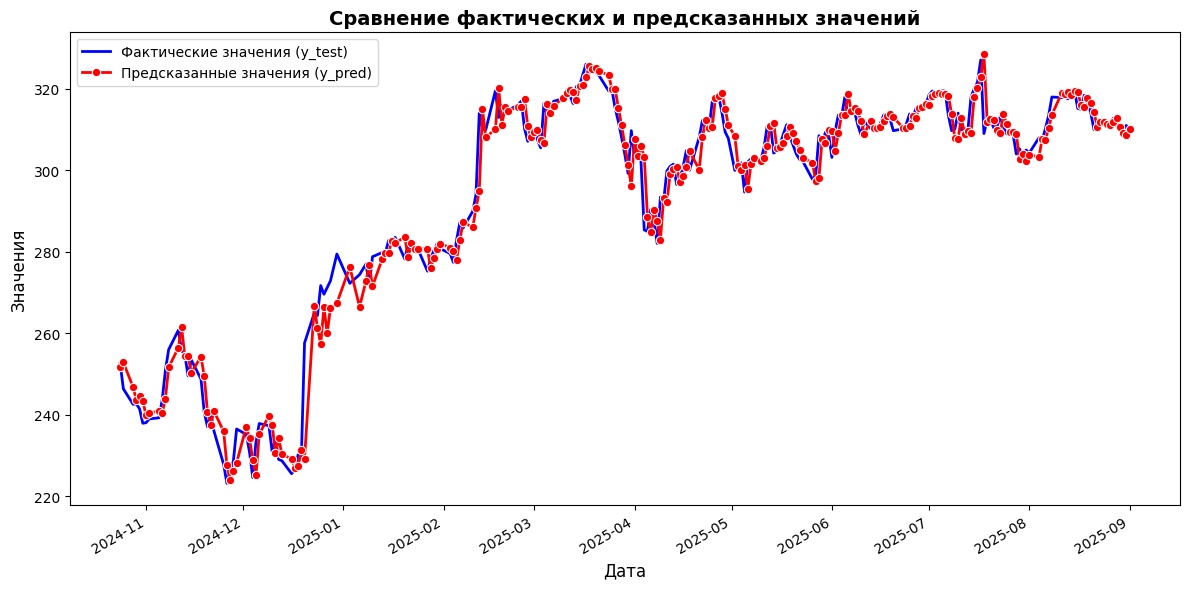

In [444]:
test_plot(y_pred, y_test)

In [82]:
def objective(trial: optuna.Trial) -> float:
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 500, 2000),
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'min_samples_split': trial.suggest_int('min_samples_split', 5, 8),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 4),
        'max_samples': trial.suggest_float('max_samples', 0.4, 0.9),
        'max_features': trial.suggest_categorical('max_features', ['sqrt']),
        'n_jobs': -1
    }

    model = RandomForestRegressor(**params)
    
    return model_time_series_validation(model, params)

In [83]:
best_params = None
least_error = None
study = optuna.create_study(
    direction='minimize', 
    sampler=optuna.samplers.TPESampler(),
    pruner=optuna.pruners.HyperbandPruner()
)
study.optimize(objective, n_trials=50, show_progress_bar=True)
print(least_error)
print(best_params)

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.09904158112336188; Test error: 0.011461303938443305
{'n_estimators': 1953, 'max_depth': 7, 'min_samples_split': 6, 'min_samples_leaf': 4, 'max_samples': 0.5651281424107701, 'max_features': 'sqrt', 'n_jobs': -1}
Train error: 0.09933218965874684; Test error: 0.011171233997005571
{'n_estimators': 1789, 'max_depth': 10, 'min_samples_split': 7, 'min_samples_leaf': 1, 'max_samples': 0.6619151060909032, 'max_features': 'sqrt', 'n_jobs': -1}
Train error: 0.10120525500567314; Test error: 0.013688404677502928
{'n_estimators': 768, 'max_depth': 4, 'min_samples_split': 7, 'min_samples_leaf': 3, 'max_samples': 0.5012496353802802, 'max_features': 'sqrt', 'n_jobs': -1}
Train error: 0.09903809384310769; Test error: 0.011957257891727075
{'n_estimators': 1486, 'max_depth': 7, 'min_samples_split': 7, 'min_samples_leaf': 1, 'max_samples': 0.4671864365925286, 'max_features': 'sqrt', 'n_jobs': -1}
Train error: 0.10191047700458992; Test error: 0.013646695516016997
{'n_estimators': 702, 'max_de

In [77]:
model = RandomForestRegressor(**best_params)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(mean_absolute_percentage_error(y_pred, y_test))

0.011611832727332634


In [78]:
model.feature_importances_

array([1.97822437e-05, 1.80151457e-01, 1.04330443e-01, 6.65106906e-02,
       5.22853355e-02, 1.25103302e-01, 1.28948312e-01, 1.64471525e-01,
       1.01045722e-01, 7.79859239e-04, 9.91428741e-04, 1.85835561e-03,
       9.40791795e-03, 2.34255965e-03, 3.44914663e-03, 4.13806604e-04,
       1.39136048e-03, 4.96678433e-04, 2.76923924e-04, 3.45795763e-04,
       5.48114071e-02, 5.68190614e-04])

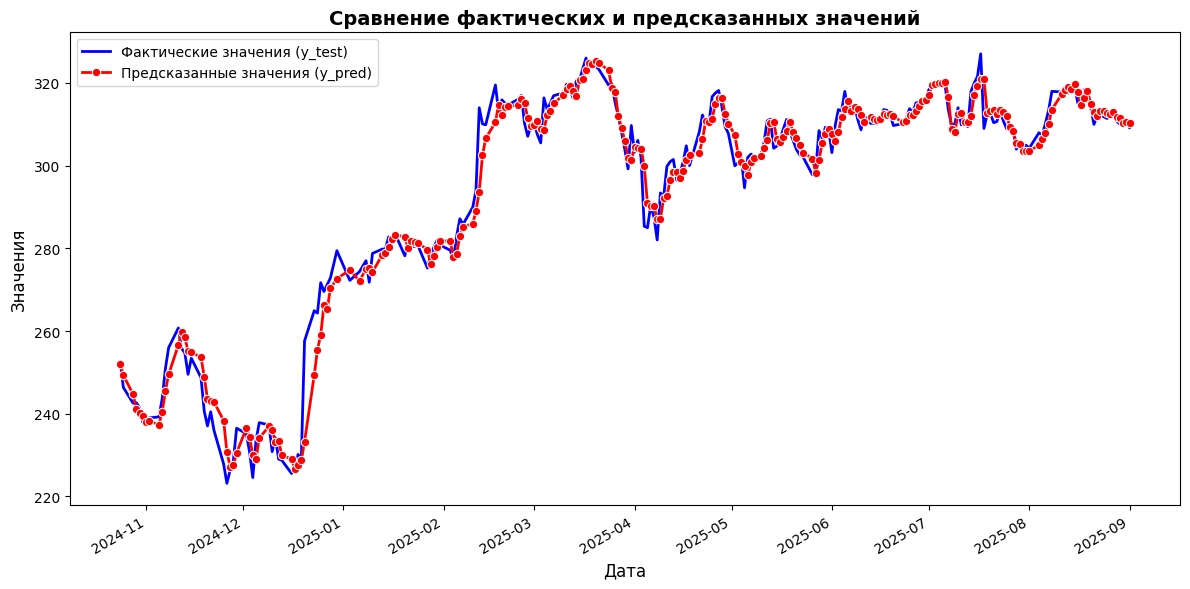

In [76]:
test_plot(y_pred, y_test)

In [77]:
def objective(trial: optuna.Trial) -> float:
    params = {
        'tree_method': trial.suggest_categorical('tree_method', ['exact']),
        'n_estimators': trial.suggest_int('n_estimators', 1500, 2000),
        'max_depth': trial.suggest_int('max_depth', 4, 8),
        'min_child_weight': trial.suggest_float('min_child_weight', 5.0, 15.0, log=True),
        'learning_rate': trial.suggest_categorical('learning_rate', [0.1]),
        'subsample': trial.suggest_float('subsample', 0.7, 0.9),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 0.9),
        'reg_lambda': trial.suggest_float('reg_lambda', 300, 500, log=True),
        'early_stopping_rounds': trial.suggest_categorical('early_stopping_rounds', [100]),
        'n_jobs': -1
    }

    model = xgb.XGBRegressor(**params)
    
    return model_time_series_validation(model, params)

In [82]:
best_params = None
least_error = None
study = optuna.create_study(
    direction='minimize', 
    sampler=optuna.samplers.TPESampler(),
    pruner=optuna.pruners.HyperbandPruner()
)
study.optimize(objective, n_trials=50, show_progress_bar=True)
print(least_error)
print(best_params)

  0%|          | 0/50 [00:00<?, ?it/s]

Train error: 0.091824911544419; Test error: 0.00944526596107518
{'tree_method': 'exact', 'n_estimators': 1955, 'max_depth': 7, 'min_child_weight': 11.789835078485858, 'learning_rate': 0.1, 'subsample': 0.7749079241178359, 'colsample_bytree': 0.773574196907063, 'reg_lambda': 429.4036592603314, 'early_stopping_rounds': 100, 'n_jobs': -1}
Train error: 0.09121919578457116; Test error: 0.009435788168080429
{'tree_method': 'exact', 'n_estimators': 1978, 'max_depth': 6, 'min_child_weight': 9.652496021352938, 'learning_rate': 0.1, 'subsample': 0.8001845347439215, 'colsample_bytree': 0.8562361903588795, 'reg_lambda': 395.90671496730994, 'early_stopping_rounds': 100, 'n_jobs': -1}
Train error: 0.0924005362363799; Test error: 0.009374460776715882
{'tree_method': 'exact', 'n_estimators': 1685, 'max_depth': 6, 'min_child_weight': 7.128885720893082, 'learning_rate': 0.1, 'subsample': 0.7716547698252512, 'colsample_bytree': 0.7082931512716245, 'reg_lambda': 328.58863465371775, 'early_stopping_rounds'

In [81]:
model = xgb.XGBRegressor(**best_params)
model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_test, y_test)], verbose=False)
y_pred = model.predict(X_test)
print(mean_absolute_percentage_error(y_pred, y_test))

0.00910017521719176


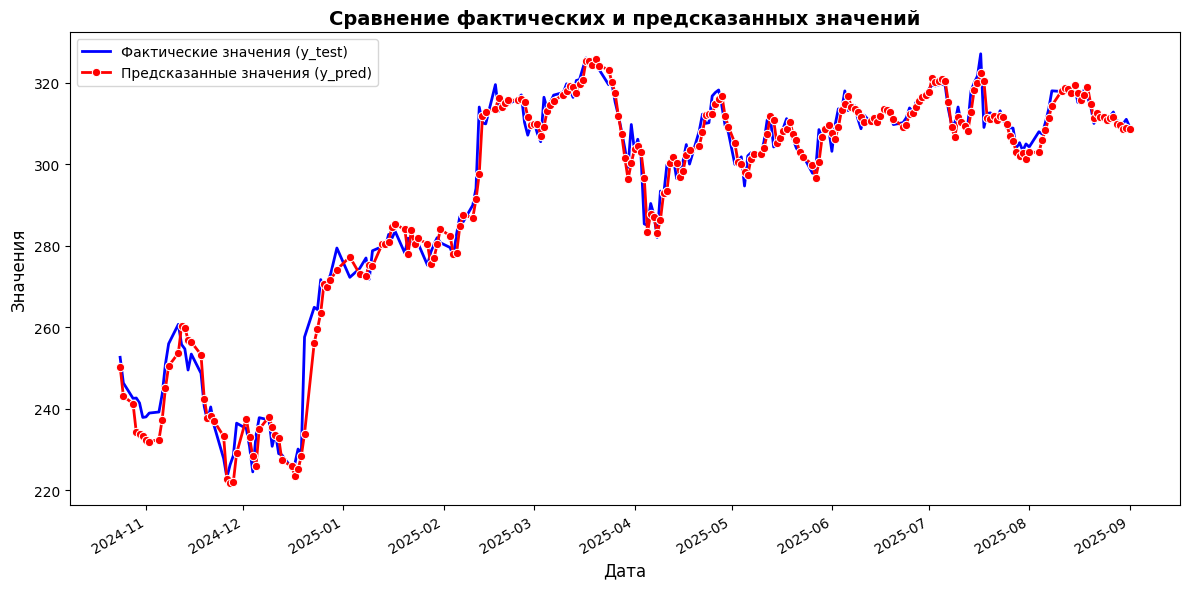

In [ ]:
test_plot(y_pred, y_test)